# Matching objectives before comparing methods

Level 3. Prerequisites: scalar prices and the control-integrity lesson. Reading time: 40 minutes.

**Question:** Which published solvers agree when given the same elastic or pure L1 objective, and what changes when the chosen penalty family is incompatible?


## Objectives

A solver comparison starts with a mathematical contract. Equal matrices and bounds are insufficient if one method prices violations quadratically and another uses a linear restoration cost. Those are different decisions even when both libraries call them soft constraints. We will therefore use two separately labeled families and compare methods only within each one. A family change will never be interpreted as an improvement in numerical accuracy.

The published generalized projection and DAQP paths cover a symmetric elastic sparse instance. The asymmetric projection, fixed-parameter FlexQP reconstruction and published ElastiQP backend cover a pure L1 instance with unequal side prices. Independent stock-OSQP lifting checks each family. The purpose is to understand objective agreement, representation size and exact-penalty meaning, not to transfer a paper's reported speedup to our machine.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

We use the product generator with development seed 1000, 32 original variables, 64 rows, row density 0.1 and unit diagonal condition. Rows are normalized to unit Euclidean length. The symmetric elastic family retains its declared hard-row mask. The L1 family explicitly has all rows soft and no quadratic side price, so it is a different authored policy with the same generator settings, not a clandestine relaxation of the first problem.

These inputs are teaching cases. They do not consume a held-out seed or tune any registered numerical setting. The scalar upper-price sweep later isolates the exact-penalty threshold in one dimension.

These generated mathematical problems and numerical exchange files are authored by Felipe Santibáñez-Leal under the MIT product terms, documented in the [public source repository](https://github.com/fsantibanezleal/CAOS_SoftQP). This lesson reads the scientific index, deployment index and C01 manifest, plus the experiment index, datasets table and one JSONL trial from their committed paths. Those saved records explain provenance and missing-value semantics; every comparison point and plotted decision is recomputed by the methods below.


In [2]:
# Read only one saved trial so the exchange example stays small.
scientific_index = json.loads((root / "data/derived/softqp/index.json").read_text(encoding="utf-8"))
deployment_index = json.loads((root / "data/derived/manifests/index.json").read_text(encoding="utf-8"))
manifest_example = json.loads((root / "data/derived/manifests/C01.json").read_text(encoding="utf-8"))
experiment_index = json.loads((root / "data/derived/experiments/index.json").read_text(encoding="utf-8"))
datasets = json.loads((root / "data/derived/experiments/datasets.json").read_text(encoding="utf-8"))
with (root / "data/derived/experiments/trials.jsonl").open(encoding="utf-8") as trial_source:
    first_trial = json.loads(trial_source.readline())


## Method

For symmetric elastic penalties, the published generalized slack projection changes the interval proximal operation while retaining the principal QP dimensions. An ordinary lift introduces auxiliary variables to express the same cost as a standard QP. DAQP instead solves a dual active-set problem and has its own reciprocal quadratic-weight convention. These algorithmic differences should leave the optimum unchanged when the original convex objective and hard policy match.

Run the authors' pinned generalized-projection implementation first. Its symmetric/unconditional assumptions are satisfied here. The asymmetric extension is unnecessary for this first instance, and replacing its side prices would obscure the question. We print actual dimensions and the original objective rather than comparing internal objective conventions.


### Matching the function before matching the implementation

Use $z=Ax$ for the original row value. For one symmetric elastic row with desired interval $C_i=[l_i,u_i]$, define $r_i(z)=z_i-\Pi_{C_i}(z_i)$. Its magnitude is distance outside the interval, with a sign that distinguishes the side. The published generalized projection uses the ordinary projection plus a proximal update of this residual:

$$T_i(v)=\Pi_{C_i}(v_i)+\operatorname{prox}_{\phi_i/\rho}\!\left(v_i-\Pi_{C_i}(v_i)\right),\qquad\rho>0.$$

This equation is used only under the published penalty assumptions. In the symmetric elastic family, $\phi_i(r)=a_i|r|+b_i r^2/2$, so the same slope and curvature apply to positive and negative departure. The side-asymmetric extension is a different proximal operation; averaging the prices to fit this equation would change the optimization question. The authors' [generalized slack projection paper](https://arxiv.org/abs/2610.35631) and the product's pinned native implementation are the sources of that numerical path.

Explicit lifting expresses the same compatible penalty by introducing nonnegative lower and upper slacks. Their inequalities are $l-s_l\leq Ax\leq u+s_u$. Linear and diagonal quadratic terms price those new variables. This expands the mathematical decision vector but makes the problem admissible to stock OSQP. The native path instead retains the original principal QP structure. Both are judged by the original evaluator; comparing their internal objectives before recovering omitted constants and slack conventions would not establish agreement.

DAQP's documented quadratic term is $s^2/(2\rho_\mathrm{soft})$, whereas the package's original-space coefficient is $b s^2/2$. The adapter therefore uses reciprocal quadratic weights, not an identical numeric argument. Its linear weights also retain distinct lower and upper meanings. The [DAQP soft-weight specification](https://darnstrom.github.io/daqp/start/advanced/soft) defines that mapping. The positive-definite Hessian in our elastic instance makes the active-set path admissible; a semidefinite replacement cannot inherit that acceptance merely because the arrays have the same dimensions.

For a pure linear finite-side family, write all admitted inequalities as $Gx\leq h$ with positive prices $w$. Both the fixed FlexQP reconstruction and ElastiQP target

$$\min_{x,s\geq0}\ \frac12x^\top Px+q^\top x+w^\top s\quad\text{subject to}\quad Gx-s\leq h.$$

This form differs from the elastic example: the quadratic soft coefficients are zero, and our comparison input has no hard inequalities. An absent side contributes no finite-side inequality and no invented slack. The FlexQP reconstruction stabilizes its numerical systems with proximal terms, but those terms do not become a scientific regularizer in this objective. ElastiQP's published implementation uses a separate active-set strategy. Their original-space objective and dual recovery are checked after execution, rather than assuming that a common word such as elastic implies common semantics.


In [3]:
# This family satisfies the published symmetric penalty assumptions.
spec = dict(n=32, density=0.1, seed=1000, family="symmetric-elastic", condition=1)
elastic = generated_problem(spec)
settings = dict(eps_abs=1e-8, eps_rel=1e-8, max_iter=200000)
native_settings = dict(settings, adaptive_rho_interval=25)
generalized = solve(elastic, "generalized", **native_settings)
print("Generalized:", generalized["dimensions"])
print(f"Elastic objective: {generalized['metrics']['objective']:.8f}")


Generalized: {'variables': 32, 'rows': 64, 'nnz': 239}
Elastic objective: -44.95315486


The active-set reference receives identical original coefficients. Its positivity requirements are satisfied by the diagonal Hessian and positive elastic quadratic weights. Unsupported conditions would require an incompatible result, not a regularizer inserted into the objective. Retaining this distinction is especially important when a semidefinite Hessian or a pure L1 side is encountered in another case.


In [4]:
# DAQP joins only because both positive-definiteness and elastic costs match.
daqp = solve(elastic, "daqp", **native_settings)
print("DAQP:", daqp["status"], daqp["dimensions"])
print(f"Active-set elastic objective: {daqp['metrics']['objective']:.8f}")


DAQP: soft optimal {'variables': 32, 'rows': 64, 'nnz': 239}
Active-set elastic objective: -44.95315485


Use independent stock lifting to close the first numerical comparison. A small original-space objective difference supports equivalence on this input. It does not prove equivalence for every penalty family, and variable counts are not a timing measurement. In particular, a lower-dimensional factorization can be offset by input validation, iteration behavior or a different implementation language.


In [5]:
# Evaluate a separately formulated QP before comparing dimensions.
elastic_lift = solve(elastic, "lifted", **native_settings)
elastic_results = [elastic_lift, generalized, daqp]
for result in elastic_results:
    difference = abs(result["metrics"]["objective"] - elastic_lift["metrics"]["objective"])
    print(result["method"], f"objective gap {difference:.3e}", result["dimensions"]["variables"])


lifted objective gap 0.000e+00 84
generalized objective gap 1.310e-08 32
daqp objective gap 1.319e-10 32


## Comparison

We now declare a pure L1 problem rather than pretending that the elastic objective fits every library. A weighted hinge is equivalent to a bounded inequality dual. FlexQP implements a fixed-parameter splitting with projection and shrinkage; ElastiQP uses its published dual active-set backend. The generalized symmetric path cannot represent these unequal side prices, and the present DAQP adapter requires positive quadratic prices. Those restrictions belong in the comparison, even though the compatible methods solve the same L1 objective.


In [6]:
# Changing the family is an explicit model decision, not an algorithmic correction.
l1 = generated_problem(dict(spec, family="asymmetric-l1"))
asymmetric_l1 = solve(l1, "asymmetric", **native_settings)
print(f"Asymmetric L1 objective: {asymmetric_l1['metrics']['objective']:.8f}")


Asymmetric L1 objective: -60.96202015


FlexQP here is an independent reconstruction of the paper's fixed equations and Algorithm 1, using sigma_x=1e-6, sigma_s=1, rho=1 and alpha=1.6. Its proximal terms stabilize subproblems without adding a quadratic scientific cost. The learned Deep FlexQP policy is absent because trained reproducibility assets were unavailable. Neither code ownership nor a paper timing result is attributed to this reconstruction.


In [7]:
# Execute the paper-equation reference on exactly the same L1 input.
flex = solve_flex(l1, **settings)
print("FlexQP:", flex["status"], flex["dimensions"])
print(f"FlexQP L1 objective: {flex['metrics']['objective']:.8f}")


FlexQP: solved {'variables': 288, 'rows': 256, 'nnz': 1116}
FlexQP L1 objective: -60.96201997


ElastiQP receives the same finite-side expansion and vector prices, with positive definite P and zero proximal objective regularization in this adapter. A hard inequality would be refused, whereas a supported hard equality would use its distinct equality interface. The exported settings make that boundary inspectable instead of silently turning every row into an elastic inequality.


In [8]:
# Published ElastiQP is a separate implementation from the FlexQP reconstruction.
elasti = solve_elastiqp(l1, **settings)
l1_lift = solve(l1, "lifted", **native_settings)
l1_results = [l1_lift, asymmetric_l1, flex, elasti]
for result in l1_results:
    gap = abs(result["metrics"]["objective"] - l1_lift["metrics"]["objective"])
    diagnostic = kkt(l1, result["x"], result["y"])
    print(result["method"], f"L1 gap {gap:.3e}",
          f"proximal defect {diagnostic['normalized_proximal_defect']:.3e}")


lifted L1 gap 0.000e+00 proximal defect 7.370e-09
asymmetric L1 gap 3.780e-08 proximal defect 3.870e-10
flex L1 gap 1.421e-07 proximal defect 4.678e-08
elastiqp L1 gap 3.833e-08 proximal defect 4.441e-16


Show the actual primal dimensions of each formulation in separate family panels. Auxiliary-variable counts describe mathematical representation. The FlexQP Schur factor dimension is smaller than its full split formulation, so its reported full variable count must not be read as the size of a single dense factor. Likewise, native projection size alone does not establish faster end-to-end execution.


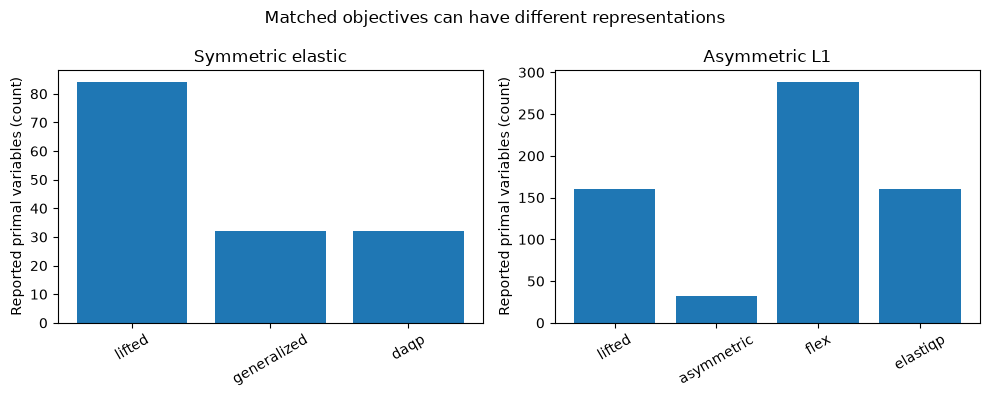

In [9]:
# Compare representation within a family, never objective values between families.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, results, title in zip(axes, [elastic_results, l1_results], ["Symmetric elastic", "Asymmetric L1"]):
    labels = [r["method"] for r in results]
    ax.bar(labels, [r["dimensions"]["variables"] for r in results])
    ax.set(title=title, ylabel="Reported primal variables (count)")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Matched objectives can have different representations")
fig.tight_layout()
plt.show()


The panels expose formulation differences after numerical agreement has been checked, rather than treating the shortest bar as a winner. Some references use finite-side slacks, while generalized projection works in the original QP dimension. Dense active-set internals and a Schur reduction do not follow directly from the displayed variable counts. The plot therefore supports a representation claim only; the registered paired campaign supplies the separate evidence needed for a computational claim.


Finally isolate exact-penalty behavior in the scalar upper case. The hard optimum is the upper boundary x=1 and its hard inequality multiplier is 2 under unit curvature and target 3. A linear weight at least that multiplier can recover the hard optimum; smaller weights intentionally purchase violation. We vary only the upper linear price and run three L1 implementations at every value.


In [10]:
# The exact-penalty threshold depends on this problem's multiplier, not a universal magic weight.
weights = np.array([0.2, 0.5, 1.2, 3.0, 6.0])
curves = {"asymmetric": [], "flex": [], "elastiqp": []}
for weight in weights:
    source = scalar(3.0, asymmetric=True)
    penalty = replace(source.penalty, upper_linear=np.array([weight]),
                      lower_quadratic=np.zeros(1), upper_quadratic=np.zeros(1))
    priced = replace(source, penalty=penalty)
    curves["asymmetric"].append(solve(priced, "asymmetric", **native_settings)["x"][0])
    curves["flex"].append(solve_flex(priced, **settings)["x"][0])
    curves["elastiqp"].append(solve_elastiqp(priced, **settings)["x"][0])
print(f"Decision at upper price 1.2: {curves['asymmetric'][2]:.6f}")


Decision at upper price 1.2: 1.800000


Plot the shared decision against price to separate solver agreement from policy behavior. Overlapping curves support the same L1 optimum within numerical tolerance. The flat segment at the hard optimum appears only after the problem-specific threshold. This example also explains why an always-solvable elastic formulation need not satisfy the original hard inequality when a practitioner deliberately chooses a low price.


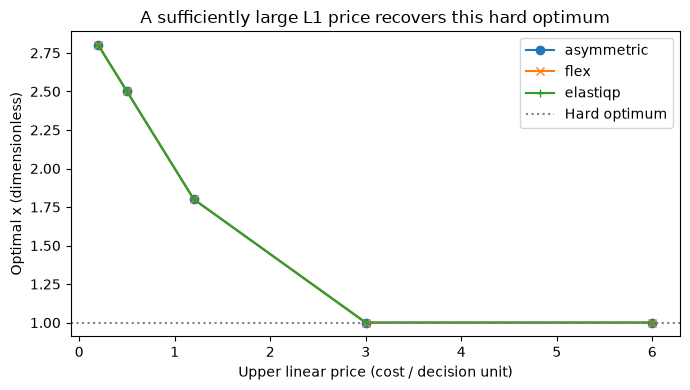

In [11]:
# Offset marker shapes reveal agreement without mixing units or objectives.
fig, ax = plt.subplots(figsize=(7, 4))
for (name, values), marker in zip(curves.items(), ["o", "x", "+"]):
    ax.plot(weights, values, marker=marker, label=name)
ax.axhline(1.0, color="gray", linestyle=":", label="Hard optimum")
ax.set(xlabel="Upper linear price (cost / decision unit)", ylabel="Optimal x (dimensionless)",
       title="A sufficiently large L1 price recovers this hard optimum")
ax.legend()
fig.tight_layout()
plt.show()


At low prices, all three methods prefer a point outside the desired interval. At sufficiently high prices, they reach its upper boundary. Their agreement does not make the low-price solution a hard-feasible solution, nor does the high-price segment prove a universal penalty constant for other QPs. Coupling, objective curvature and row scaling change optimal multipliers. The result is an exact-penalty lesson on a stated scalar problem, not a certification of a learned policy.


### Using it on your own data

Before admitting another sparse instance, record the penalty family, finite sides, hard mask, dimensions and convexity assumptions alongside the matrices. The `generated_problem` call below uses a declared development seed and unit row normalization; it is an instructional family, not a draw from the registered held-out population. To use a measured application problem, construct a `Problem` from its actual sparse coefficients and validate the row units and prices before choosing a method. Do not change a hard inequality into a finite-price side merely to make an otherwise incompatible backend run.

The scientific index read above gives `default_case`, `cases`, `environment`, `state` and `limitations`; each case entry binds its relative result path and SHA-256. The outer deployment index supplies the inventory `files`, case-manifest paths, `n_cases` and `engine_version`. A case manifest then names its result artifact with path, byte count and digest, and carries `lane`, engine identity and gate information. Those layers answer which data was deployed, which mathematical case it describes and how its bytes are identified. None certifies that a displayed faster method solved the same objective.

The experiment index separately lists `protocol_id`, `state` and `artifacts`. Each artifact entry names its schema, bytes and hash. The datasets table keeps `id`, `split`, `n`, `density`, `condition`, `family`, `seed`, `problem_sha256` and oracle outcome. A raw trial keeps that instance identity beside `method`, `repetition`, `warmup`, `state`, `reason`, `metrics`, `normalized_gap` and separate elapsed/setup/update fields. A missing metric on an incompatible trial is meaningful; converting it to zero would create a falsely perfect comparison. The first saved trial printed here illustrates that refusal without substituting any archived output for the freshly executed comparison.

The deterministic pipeline constructs inputs, evaluates each returned candidate in original coordinates and exports all method states. It has no training operation or fitted model for these solvers; the documented learned Deep FlexQP policy remains unavailable. The inference operation here is a mathematical solve, not prediction from an untrained surrogate. A developer extending the pipeline should keep the compatibility decision before numerical execution and the original-space acceptance after it, with failure and missing values preserved across export.


In [12]:
# Show the distinct indexes and a refusal record without substituting archived decisions.
print('Scientific index', scientific_index["schema_version"], sorted(scientific_index["cases"][0]))
print('Deployment and manifest', deployment_index["schema"], manifest_example["schema"],
      sorted(manifest_example["artifact"]))
print('Experiment index', experiment_index["schema_version"], sorted(experiment_index["artifacts"][0]))
print('Dataset fields', sorted(datasets[0]))
print('First saved trial', first_trial["state"], first_trial["reason"], first_trial["metrics"])


Scientific index softqp.index/v1 ['case_id', 'category', 'failed', 'path', 'sha256', 'title']
Deployment and manifest softqp.artifact-index/v1 softqp.manifest/v1 ['bytes', 'format', 'path', 'sha256']
Experiment index softqp.experiments/v1 ['bytes', 'path', 'schema', 'sha256']
Dataset fields ['condition', 'density', 'family', 'generation_seconds', 'id', 'n', 'oracle_objective', 'oracle_reason', 'oracle_state', 'problem_sha256', 'seed', 'split']
First saved trial incompatible FlexQP reconstruction relaxes its inequalities; original hard rows are not softened None


### Sensitivity and the boundary of this comparison

The preceding scalar price sweep changes the optimization policy rather than a tolerance. At the hard upper optimum $x=1$, the objective derivative without the penalty is $1-3=-2$, so the problem-specific upper multiplier is two. A positive linear price below that threshold permits departure; at or above it the hard optimum is recovered in this strictly convex example. That threshold changes with curvature, row scaling and coupling. It is not a transferable constant for control or energy applications.

The third figure compares the returned primal vectors against the independent lift within each sparse family. This supplements objective agreement: two points can have similar costs while differing along weakly curved directions. The symmetric logarithmic axis retains an exact zero rather than fabricating a tiny positive error for plotting. These discrepancies are numerical diagnostics at the stated tolerances, not statistical confidence intervals. A valid uncertainty interval for speed would require the registered paired protocol, repeated observations and the retained failures, which this instructional run deliberately does not replace.


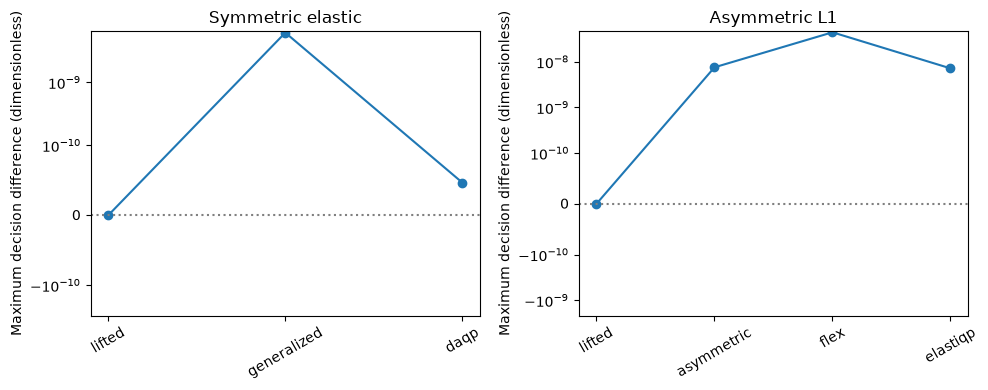

In [13]:
# Compare primal agreement with an independent formulation inside each family.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
families = [elastic_results, l1_results]
references = [elastic_lift, l1_lift]
titles = ['Symmetric elastic', 'Asymmetric L1']
for ax, results, reference, title in zip(axes, families, references, titles):
    errors = [np.max(np.abs(np.asarray(r["x"]) - reference["x"])) for r in results]
    ax.plot([r["method"] for r in results], errors, marker="o")
    ax.axhline(0, color="gray", linestyle=":")
    ax.set_yscale("symlog", linthresh=1e-10)
    ax.set(ylabel='Maximum decision difference (dimensionless)', title=title)
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


The two panels retain distinct mathematical families and their own independent lifted reference. Small primal discrepancies support agreement on these generated instances while leaving each backend's assumptions visible. The zero line is exact and the near-zero region is linear, so a method with a zero difference is not assigned an artificial error floor. The chart says nothing about which formulation is fastest, and it cannot extend ElastiQP or the fixed FlexQP reconstruction to unsupported hard inequalities or quadratic soft costs.


## Results

**Answer:** At upper linear price 1.2, the scalar pure L1 optimum is 1.800000, rather than the elastic example's 1.160000. That change is a different objective. Within each sparse family, the printed original-space gaps and proximal diagnostics quantify agreement between the compatible published paths and their independent lift. The plots distinguish representation size from solution policy, and neither supplies a timing ranking.

Deep FlexQP remains a documented unavailable comparator. A learned-policy result has not been fabricated, and the fixed-parameter reconstruction is not labeled as a reproduction of its trained acceleration.


## Summary

First match the objective, finite sides, hard policy and original units; then interpret each backend's status and recover its dual signs. Preserve incompatible cases in the record. Only after those checks is a common computational protocol meaningful. The next lesson tests such a protocol's candidate claim, including the possibility that correct mathematics and smaller matrices still fail to produce a useful time reduction.


## References

- [Generalized slack projections](https://arxiv.org/abs/2610.35631).
- [DAQP original-scale soft weights](https://darnstrom.github.io/daqp/start/advanced/soft).
- [Oshin et al., FlexQP equations and Algorithm 1](https://arxiv.org/html/2512.01565v2).
- [Published ElastiQP implementation](https://github.com/StanfordASL/elastiqp).

- [OSQP formulation and residuals](https://osqp.org/docs/solver/).
- [SoftQP matched-objective technical report](https://doi.org/10.5281/zenodo.23851659).
